# Pricing: capacidad y presupuesto de pérdida

## Resumen
Caso sintético con precio único por período. La decisión sujeta a CVaR90%shortfall≤500 elige precio18; la política neutral elige22. El gate sacrifica beneficio esperado para respetar el presupuesto. No estima elasticidades ni demuestra rentabilidad real.

## Método y supuestos
Demanda fluida por escenario: D_s(p)=m_s sigmoid(5−0,25p). Se sirve min(capacidad,D); beneficio=(p−c)servido−F. Capacidad300, costo variable4 y fijo evitable1000. Detener no incurre costos. Precio único exante aplicado a todos escenarios; sin personalización ni discriminación.

Riesgo=CVaR90% de shortfall max(−beneficio,0). La cola promedia exactamente10%de masa, partiendo átomos cuando corresponde. No se usa media de pérdidas≥VaR, que falla con átomos. Se enumera menú finito; no óptimo continuo ni pricing dinámico.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
cfg=json.loads(Path('config.json').read_text())
summary=json.loads(Path('results/summary.json').read_text())
display(cfg)

{'seed': 20261025,
 'prices': [8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32, 34, 36, 38, 40],
 'capacity': 300,
 'unit_cost': 4,
 'fixed_cost': 1000,
 'alpha': 0.9,
 'budget': 500,
 'scenarios': [{'name': 'high', 'weight': 0.6, 'arrivals': 1000},
  {'name': 'medium', 'weight': 0.25, 'arrivals': 250},
  {'name': 'stress', 'weight': 0.15, 'arrivals': 60}],
 'units': 'synthetic monetary units per period; demand is fluid expected transactions, not observed customers',
 'hypothesis': 'constrained choice respects CVaRshortfall<=500, compared with unconstrained same scenario model'}

## Resultados y baselines
Todos son escenarios sintéticos conocidos antes de decidir. Benchmark plug-in usa demanda media y luego se evalúa con los mismos escenarios. Neutral maximiza beneficio esperado con capacidad sin presupuesto de cola.

{'constrained': {'price': 18,
  'expected_profit': 2143.0817905330564,
  'cvar_shortfall': 477.13416179044214,
  'scenario_profits': [3200, 1178.607659206491, -477.13416179044214]},
 'risk_neutral': {'price': 22,
  'expected_profit': 2725.894840743213,
  'cvar_shortfall': 592.2560776980029,
  'scenario_profits': [4400, 698.9330095916546, -592.2560776980029]},
 'plugin_prediction': {'price': 20,
  'expected_profit': 3800,
  'cvar_shortfall': 0.0,
  'scenario_profits': [3800]},
 'plugin_actual': {'price': 20,
  'expected_profit': 2452.0,
  'cvar_shortfall': 520.0,
  'scenario_profits': [3800, 1000.0, -520.0]},
 'mc_mean': 2141.3922402160506,
 'mc_se': 3.1104459994257114,
 'replicates': 200000,
 'selector_seconds': 0.0007848089999242802,
 'selector_python_peak_bytes': 4832,
 'seed': 20261025,
 'python': '3.12.14',
 'platform': 'Linux-6.18.55-x86_64-with-glibc2.39',
 'numpy': '2.3.5'}

,price,expected_profit,cvar_shortfall,high_profit,medium_profit,stress_profit
0,stop,0.000,0.000,0.000,0.000,0.000
1,8,-7.564,771.382,200.000,-47.426,-771.382
2,10,476.457,667.309,800.000,386.213,-667.309
3,12,943.816,577.217,1400.000,761.594,-577.217
4,14,1384.566,509.455,2000.000,1043.936,-509.455
5,16,1787.248,473.638,2600.000,1193.176,-473.638
6,18,2143.082,477.134,3200.000,1178.608,-477.134
7,20,2452.000,520.000,3800.000,1000.000,-520.000
8,22,2725.895,592.256,4400.000,698.933,-592.256
9,24,2611.883,677.270,4378.828,344.707,-677.270


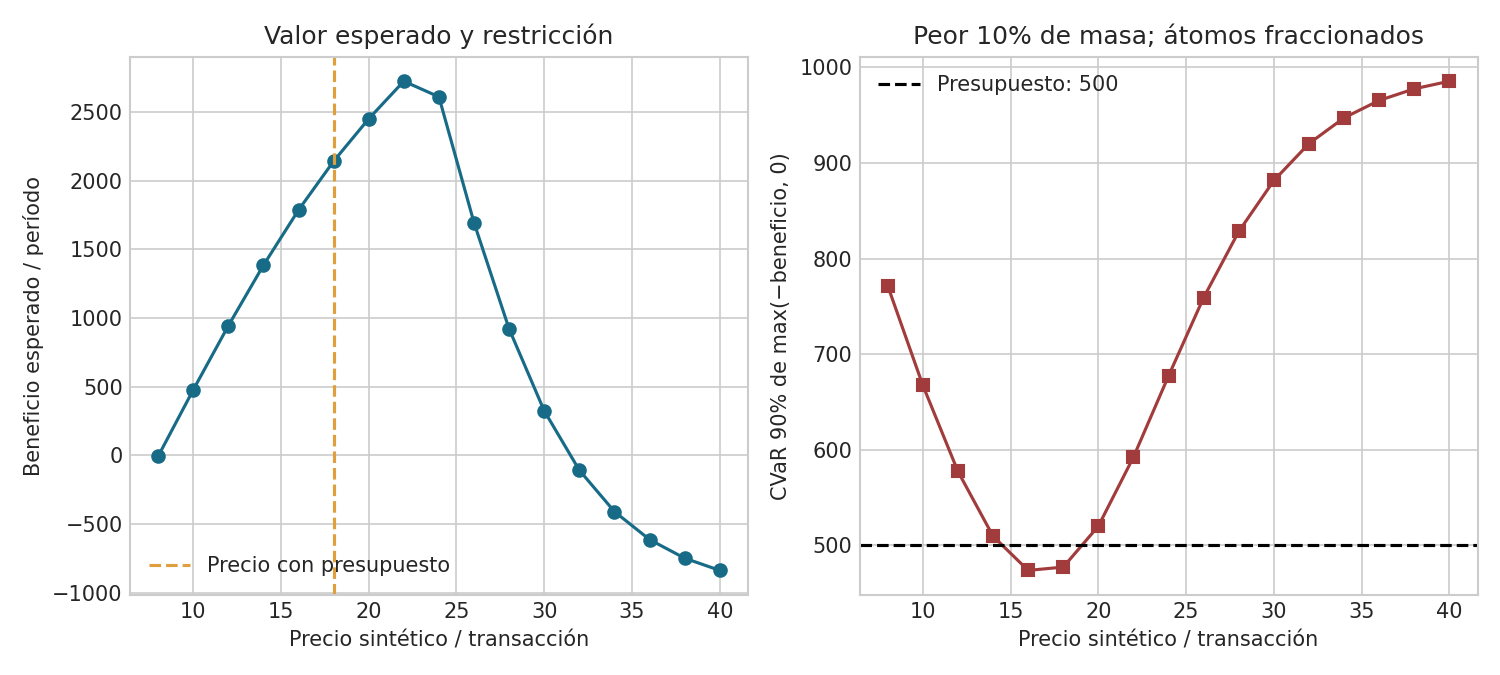

In [2]:
display(summary)
display(pd.read_csv('results/prices.csv').round(3))
display(Image(filename='results/pricing-frontier.png'))

## Validación y sensibilidad
Tests contrastan CVaR con LP independiente, incluyen fracción de átomo, traslación/homogeneidad y presupuesto anidado. MC200000 evalúa media bajo los tres escenarios, no incertidumbre real. Un presupuesto estricto puede recomendar detener. El menú fino1601 elige19,26 yvalor2342,66: el18solo es óptimo del menúconfigurado, no continuo.

In [3]:
display(pd.read_csv('results/sensitivity.csv').round(3))
display(pd.read_csv('results/scaling.csv').round(4))
assert summary['constrained']['cvar_shortfall']<=cfg['budget']
assert summary['constrained']['expected_profit']<=summary['risk_neutral']['expected_profit']
assert abs(summary['mc_mean']-summary['constrained']['expected_profit'])<5*summary['mc_se']

,capacity,budget,price,expected_profit,cvar_shortfall
0,100,0,NaN,0.000,0.000
1,100,300,NaN,0.000,0.000
2,100,500,18.0,268.430,477.134
3,100,1000,28.0,644.552,828.348
4,300,0,NaN,0.000,0.000
5,300,300,NaN,0.000,0.000
6,300,500,18.0,2143.082,477.134
7,300,1000,22.0,2725.895,592.256
8,600,0,NaN,0.000,0.000
9,600,300,NaN,0.000,0.000


,menu_size,median_seconds,selected_price,expected_profit,cvar_shortfall
0,17,0.0001,18.00,2143.0818,477.1342
1,161,0.0010,19.20,2333.5596,498.5514
2,1601,0.0101,19.26,2342.6645,499.9739


## Decisión y límites
Continuar piloto controlado a precio propuesto solo si costos, capacidad y demanda son defendibles; ajustar al cambiar elasticidad/mezcla/costo; detener si el menú no crea valor dentro presupuesto. Demanda fluida fraccional no son ventas observadas; omite aleatoriedad individual, competencia, causalidad, dinámica y costos hundidos. Referencias y análisis crítico en informe.md.